# To what extent were employee performance ratings associated with compensation in 2024, and did that relationship differ across departments?

# 1. Import SQL query results for analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from google.cloud import bigquery

client = bigquery.Client(
    project="employee-data-project-507314"
)

#This query brings in a joined table across performance_reviews, employees, departments, and compensation 

query = """


-- Establish a master table from which to pull and perform calculations. 
-- This version pulls through department as well as performance rating.

WITH joined_table AS (
    SELECT 
        pr.review_id,
        pr.employee_id,
        jr.role_title,
        d.department_name,
        pr.review_year,
        pr.performance_rating,
        pr.promotion_flag,
        c.annual_salary
    FROM 
        `employee-data-project-507314.employee_dataset.performance_reviews` pr
    
    JOIN
        `employee-data-project-507314.employee_dataset.compensation` c
    ON
        pr.employee_id = c.employee_id
    
    JOIN
        `employee-data-project-507314.employee_dataset.employees` e
    ON
        pr.employee_id = e.employee_id

    JOIN
        `employee-data-project-507314.employee_dataset.departments` d
    ON
        e.department_id = d.department_id

    JOIN
        `employee-data-project-507314.employee_dataset.job_roles` jr
    ON
        e.role_id = jr.role_id

    WHERE
        pr.review_year = 2024
),

-- SELECT * FROM joined_table

-- Establish a column that shows mean salary from master table.

salary_summary AS (
    SELECT
        department_name,
        role_title,
        performance_rating,
        COUNT(DISTINCT employee_id) AS employee_count,
        AVG(annual_salary) AS mean_salary
    FROM 
        joined_table
    GROUP BY
        department_name,
        role_title,
        performance_rating
),

-- Establish a column that shows median salary from master table.

median_summary AS (
    SELECT DISTINCT
        department_name,
        role_title,
        performance_rating,
        PERCENTILE_CONT(annual_salary, 0.5) OVER (
            PARTITION BY 
                department_name,
                role_title,
                performance_rating
        ) AS median_salary
    FROM 
        joined_table
)

-- Pull through final result. Select columns from calculated tables and aggregate by department, role title, and performance rating to show any relationship between performance and compensation across each department.

SELECT
    s.department_name,
    s.role_title,
    s.performance_rating,
    s.employee_count,
    ROUND(s.mean_salary, 2) AS mean_salary,
    ROUND(m.median_salary, 2) AS median_salary
FROM 
    salary_summary s
JOIN 
    median_summary m
USING 
    (
        department_name,
        role_title,
        performance_rating
    )
ORDER BY 
    s.department_name,
    s.role_title,
    s.performance_rating;
    
    
"""

# Convert query results to pd dataframe

df = client.query(query).to_dataframe()

### 1.1. Display head of table to validate correct pull-through

In [2]:
df.head()

,department_name,role_title,performance_rating,employee_count,mean_salary,median_salary
0,Customer Support,Customer Support Advisor,High,35,27400.00,27000.0
1,Customer Support,Customer Support Advisor,Low,21,27761.90,27000.0
2,Customer Support,Customer Support Advisor,Meets,117,27794.87,28000.0
3,Data & BI,BI Analyst,High,2,57500.00,57500.0
4,Data & BI,BI Analyst,Low,3,48333.33,47000.0


# 2. Exploratory Data Analysis - Create effective tables for comparison

## 2.1. Establish a pivot table to show the difference in % for mean values - Low and High vs Meets

In [3]:
# Establish a pivot to calculate mean salary separately

mean_salary_pivot = df.pivot(
    index = ["department_name", "role_title"],
    columns = "performance_rating",
    values = "mean_salary"
)

# Reorder columnns to make more sense

mean_salary_pivot = mean_salary_pivot [
    ["Low",
    "Meets",
    "High"]
    ]

# Establish a column to compare 'low' perf rating mean salary to 'meet'.

mean_salary_pivot["Low vs Meets (%)"] = ((
    (mean_salary_pivot["Low"] - mean_salary_pivot["Meets"])
    / mean_salary_pivot["Meets"]
) * 100
).round(2)

# Establish a column to compare 'high' perf rating mean salary to 'meet'.

mean_salary_pivot["High vs Meets (%)"] = ((
    (mean_salary_pivot["High"] - mean_salary_pivot["Meets"])
    / mean_salary_pivot["Meets"]
) * 100
).round(2)

# Reorder results by Meets average salary

mean_salary_pivot = mean_salary_pivot.sort_values(by="Meets")

mean_salary_pivot

,performance_rating,Low,Meets,High,Low vs Meets (%),High vs Meets (%)
department_name,role_title,,,,,
Customer Support,Customer Support Advisor,27761.90,27794.87,27400.00,-0.12,-1.42
HR,HR Administrator,32200.00,31476.19,30125.00,2.30,-4.29
Sales,Sales Executive,36466.67,35662.65,34733.33,2.25,-2.61
Marketing,Marketing Executive,35666.67,35666.67,37166.67,0.00,4.21
Payroll,Payroll Specialist,39400.00,37928.57,40625.00,3.88,7.11
Operations,Operations Analyst,39884.62,40539.22,40333.33,-1.61,-0.51
Finance,Finance Analyst,36000.00,41888.89,38800.00,-14.06,-7.37
IT,Systems Administrator,43800.00,45189.19,45142.86,-3.07,-0.10
Data & BI,Data Analyst,42333.33,46192.31,45400.00,-8.35,-1.72


In [4]:
# Drop raw salary values to leave percentage comparison values

mean_salary_pivot = mean_salary_pivot.drop(columns = ["Low", "Meets", "High"])

mean_salary_pivot

,performance_rating,Low vs Meets (%),High vs Meets (%)
department_name,role_title,,
Customer Support,Customer Support Advisor,-0.12,-1.42
HR,HR Administrator,2.30,-4.29
Sales,Sales Executive,2.25,-2.61
Marketing,Marketing Executive,0.00,4.21
Payroll,Payroll Specialist,3.88,7.11
Operations,Operations Analyst,-1.61,-0.51
Finance,Finance Analyst,-14.06,-7.37
IT,Systems Administrator,-3.07,-0.10
Data & BI,Data Analyst,-8.35,-1.72


## 2.2. Establish a pivot table to show the difference in % for median values - Low and High vs Meets

In [5]:
# Establish a pivot to calculate median salary separately

median_salary_pivot = df.pivot(
    index = ["department_name", "role_title"],
    columns = "performance_rating",
    values = "median_salary"
)

# Reorder columnns to make more sense

median_salary_pivot = median_salary_pivot [
    ["Low",
    "Meets",
    "High"]
    ]

# Establish a column to compare 'low' perf rating median salary to 'meet'.

median_salary_pivot["Low vs Meets (%)"] = ((
    (median_salary_pivot["Low"] - median_salary_pivot["Meets"])
    / median_salary_pivot["Meets"]
) * 100
).round(2)

# Establish a column to compare 'high' perf rating median salary to 'meet'.

median_salary_pivot["High vs Meets (%)"] = ((
    (median_salary_pivot["High"] - median_salary_pivot["Meets"])
    / median_salary_pivot["Meets"]
) * 100
).round(2)

# Reorder results by Meets average salary

median_salary_pivot = median_salary_pivot.sort_values(by="Meets")

median_salary_pivot

,performance_rating,Low,Meets,High,Low vs Meets (%),High vs Meets (%)
department_name,role_title,,,,,
Customer Support,Customer Support Advisor,27000.0,28000.0,27000.0,-3.57,-3.57
HR,HR Administrator,32000.0,32000.0,29500.0,0.00,-7.81
Sales,Sales Executive,36000.0,35000.0,35000.0,2.86,0.00
Marketing,Marketing Executive,36000.0,35500.0,37500.0,1.41,5.63
Payroll,Payroll Specialist,41000.0,38500.0,41000.0,6.49,6.49
Operations,Operations Analyst,39500.0,40000.0,40000.0,-1.25,0.00
Finance,Finance Analyst,36000.0,42000.0,37000.0,-14.29,-11.90
IT,Systems Administrator,42000.0,46000.0,47000.0,-8.70,2.17
Data & BI,Data Analyst,43000.0,47000.0,47500.0,-8.51,1.06


In [6]:
# Drop raw salary values to leave percentage comparison values

median_salary_pivot = median_salary_pivot.drop(columns = ["Low", "Meets", "High"])

median_salary_pivot

,performance_rating,Low vs Meets (%),High vs Meets (%)
department_name,role_title,,
Customer Support,Customer Support Advisor,-3.57,-3.57
HR,HR Administrator,0.00,-7.81
Sales,Sales Executive,2.86,0.00
Marketing,Marketing Executive,1.41,5.63
Payroll,Payroll Specialist,6.49,6.49
Operations,Operations Analyst,-1.25,0.00
Finance,Finance Analyst,-14.29,-11.90
IT,Systems Administrator,-8.70,2.17
Data & BI,Data Analyst,-8.51,1.06


# 3. Display findings in a medium that conveys any relationships visually.

## 3.1. Show 'Low vs Meets' mean difference as a bar graph

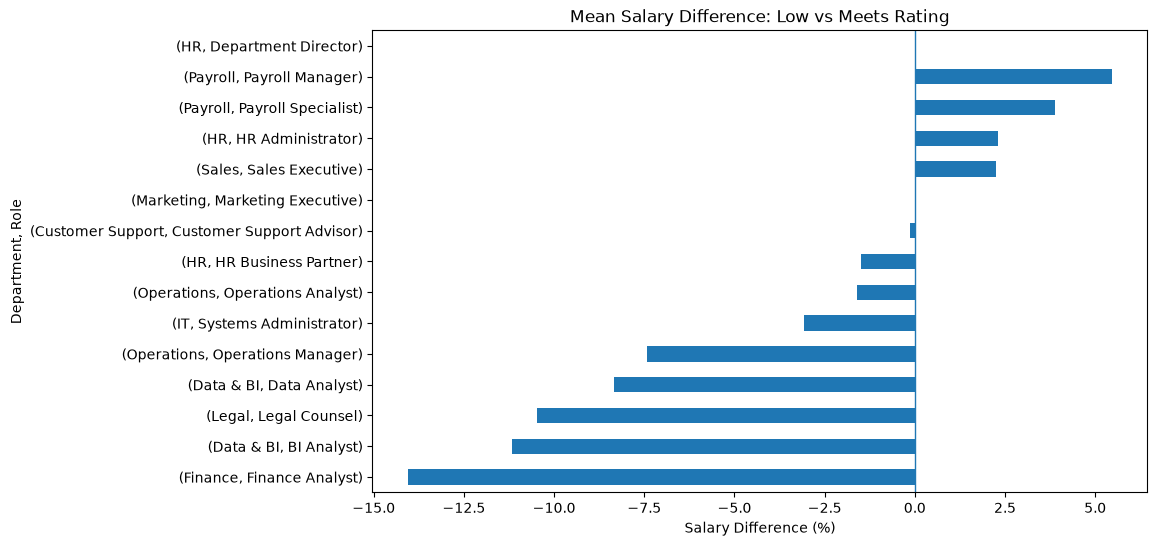

In [7]:
# Create a horizontal bar chart

mean_low = mean_salary_pivot["Low vs Meets (%)"].sort_values().plot(
    kind = "barh",
    figsize = (10, 6)
)

# Add a vertical line at zero

plt.axvline(x = 0, linewidth = 1)

# Add chart labels

plt.title("Mean Salary Difference: Low vs Meets Rating")
plt.xlabel("Salary Difference (%)")
plt.ylabel("Department, Role")

# Display the chart

plt.show()


### 3.1.a. Figures should be negative here. Positive figures indicate roles that are being paid more despite having 'Low' performance ratings.

### We can see here that 9 of 15 departments paid 'Low' performing employees less than those who meet targets. Marketing Executives were paid exactly the same whther 'Low' or 'Meets'. 

### However, both payroll roles, HR Administrators, and Sales Executives paid those who failed to meet performance expectations more on average. This warrants a further investigation of the pay structure in these three departments.

### One important omission was HR Department Directors, none of whom scored a 'Low', and so received a NaN value here.

## 3.2. Show 'High vs Meets' mean difference as a bar graph

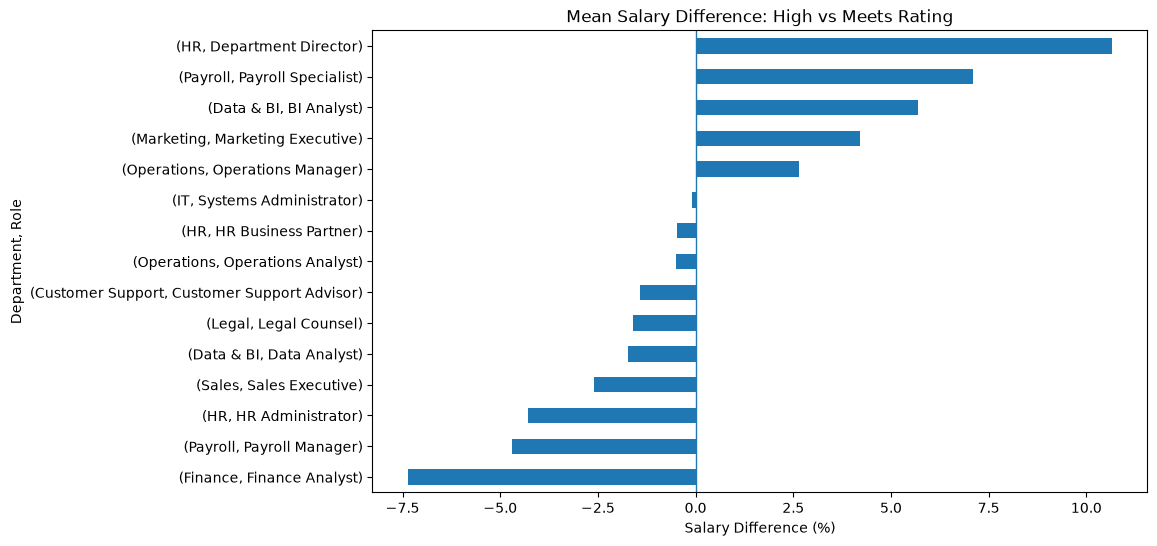

In [8]:
# Create a horizontal bar chart

mean_high = mean_salary_pivot["High vs Meets (%)"].sort_values().plot(
    kind = "barh",
    figsize = (10, 6)
)

# Add a vertical line at zero

plt.axvline(x = 0, linewidth = 1)

# Add chart labels

plt.title("Mean Salary Difference: High vs Meets Rating")
plt.xlabel("Salary Difference (%)")
plt.ylabel("Department, Role")

# Display the chart

plt.show()


### 3.2.a. Figures should be positive here. Negative figures indicate departments that are being paid less despite having 'High' performance ratings.

### We can see here that only 5 of 15 job roles paid employees who exceeded expectations more than those who just met targets. Inversely, every department except Marketing have roles where high-performers are actively paid less than those who form a baseline of meeting targets. 

### These patterns may warrant further investigation, particularly where higher-rated employees have lower average or median salaries than employees rated Meets. However, salary differences may also reflect tenure, experience, pay bands, or other factors not examined here.

## 3.3. Show 'Low vs Meets' median difference as a bar graph

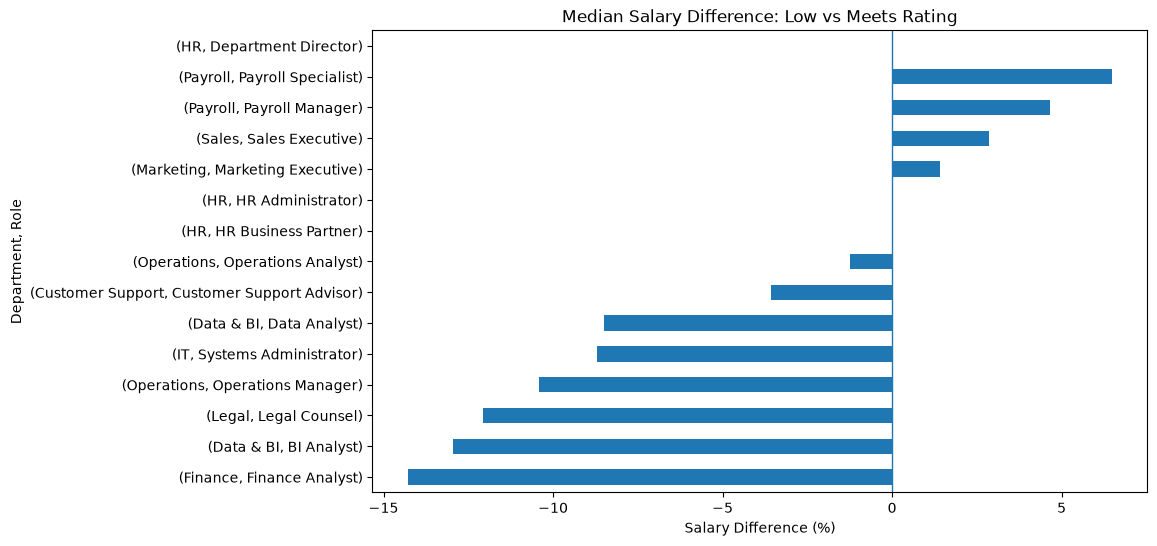

In [9]:
# Create a horizontal bar chart

median_low = median_salary_pivot["Low vs Meets (%)"].sort_values().plot(
    kind = "barh",
    figsize = (10, 6)
)

# Add a vertical line at zero

plt.axvline(x = 0, linewidth = 1)

# Add chart labels

plt.title("Median Salary Difference: Low vs Meets Rating")
plt.xlabel("Salary Difference (%)")
plt.ylabel("Department, Role")

# Display the chart

plt.show()


### 3.3.a. Again, values should be negative here if we assume a desired merit-based pay structure.

### These results align roughly with the mean results. This suggests that the overall patterns are not solely driven by differences in the mean, although sample sizes and other factors should still be considered.

## 3.4. Show 'High vs Meets' median difference as a bar graph

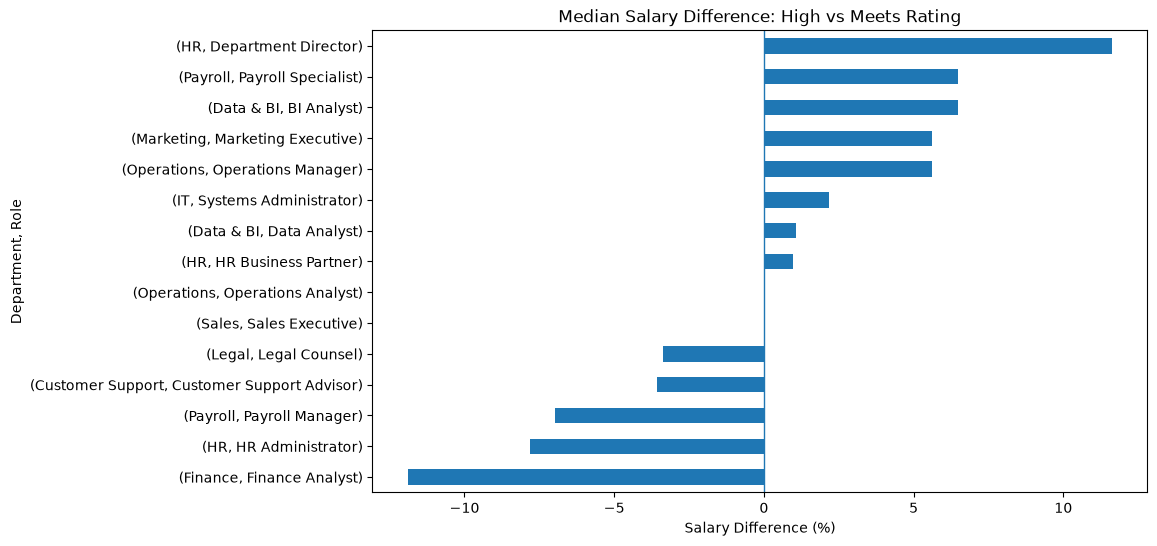

In [10]:
# Create a horizontal bar chart

median_high = median_salary_pivot["High vs Meets (%)"].sort_values().plot(
    kind = "barh",
    figsize = (10, 6)
)

# Add a vertical line at zero

plt.axvline(x = 0, linewidth = 1)

# Add chart labels

plt.title("Median Salary Difference: High vs Meets Rating")
plt.xlabel("Salary Difference (%)")
plt.ylabel("Department, Role")

# Display the chart

plt.show()


### 3.4.a. Again, values should be positive here if we assume a desired merit-based pay structure.

### When comparing to mean values, there is a small amount of movement in the middle of the chart, pushing some roles like IT Systems Administrators, Data Analysts, and HR Business Partners into the positive. These differences may be influenced by the number of employees in each rating group. Reviewing group sizes would help establish how much confidence to place in these comparisons.

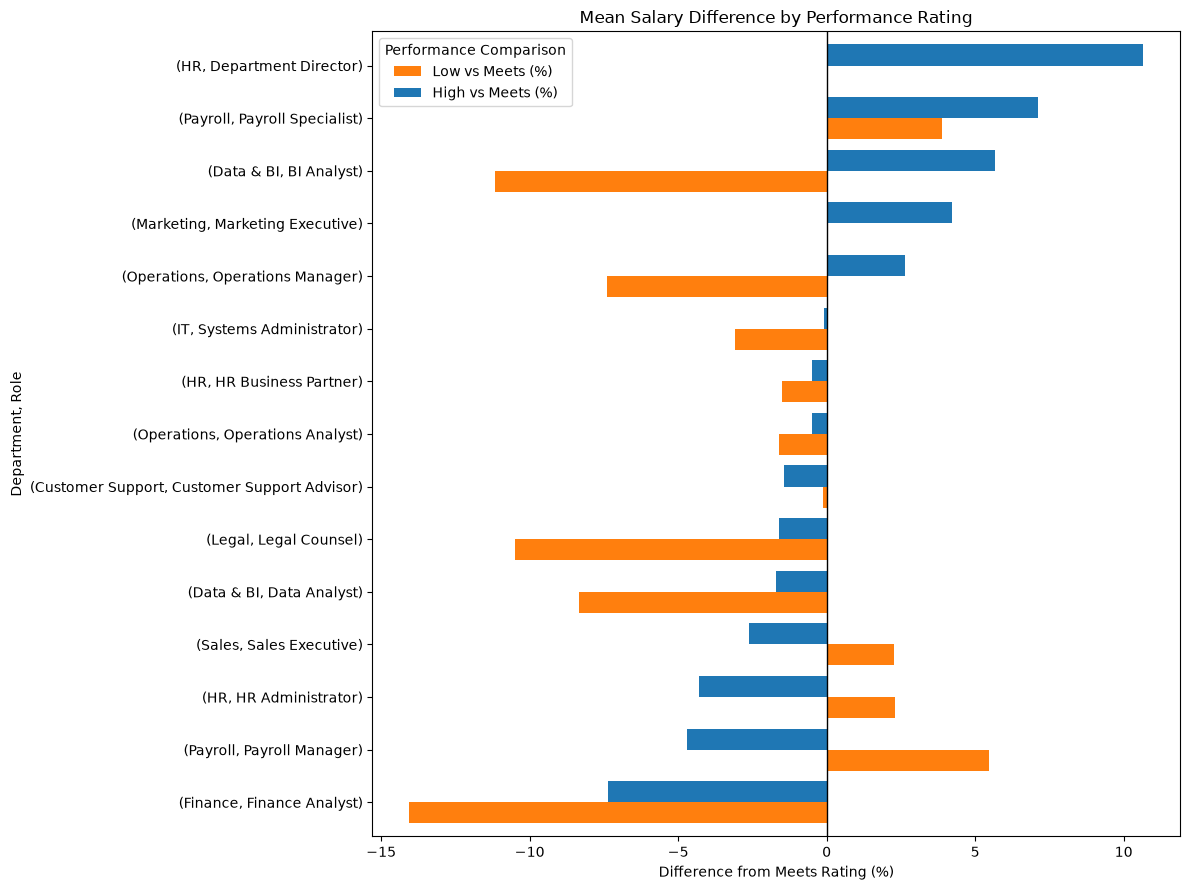

In [11]:
# Sort roles by High vs Meets percentage difference
ax = mean_salary_pivot.sort_values(
    by="High vs Meets (%)",
    ascending=True
)

# Create a bar chart comparing both figures for each role.

ax = ax[
    ["Low vs Meets (%)", "High vs Meets (%)"]
].plot(
    kind="barh",
    figsize=(12, 9),
    width=0.8,
    color=["tab:orange", "tab:blue"]
)

ax.axvline(x=0, color="black", linewidth=1)

ax.set_title("Mean Salary Difference by Performance Rating")
ax.set_xlabel("Difference from Meets Rating (%)")
ax.set_ylabel("Department, Role")

# Explicitly use the two bar series for the legend

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, title="Performance Comparison")

plt.tight_layout()
plt.show()


# 4. Findings

## We would hope to each role within each department score negative relative percentages values in 'Low vs Meets' charts, and positive values in 'High vs Meets' charts. This pattern would be consistent with a compensation structure in which higher performance ratings are associated with higher salaries, and lower ratings with lower salaries. However, these descriptive comparisons alone cannot establish the actual strength of the statistical relationship or determine whether performance ratings influence compensation concretely.

## However, this is not the case. In fact, in mean salary comparison, the only roles for which we see results consistent with this is for BI Analysts within the Data & BI department, and Operations Managers within the Operations department. Both of these roles display higher salaries for higher-performing employees, and vice versa. In median salary comparison, Data Analyst and IT Systems Administrator position also suggest this pattern.

## Some roles saw a stark inverse relationship between performance and compensation - for example Payroll Managers and HR Administrators. Others, like Finance Analysts, were paid drastically worse whether they performed better or worse than usual.

## The roles of BI Analyst and Operations Managers should be examined to inform on a pay structure which rewards competency and performance. Even these departments warrant further investigation, as other roles within these departments do not support this.

## It is important to consider that the employee count in each of these varies strongly, and even more for ther performance rating groups within them. Further consideration of sample size should be considered before drawing concrete conclusions about pay structure. For the purposes of this investigation, these findings provide a useful basis for further, more detailed examination of the organisation’s compensation structure.